# 02 — Phân Tích Khám Phá Dữ Liệu (Exploratory Data Analysis - EDA)

**Đề tài:** Nghiên cứu và trực quan hóa các đặc trưng âm thanh và tương quan với các vấn đề xã hội. Phân tích dự đoán xu hướng bài hát thịnh hành trên Spotify  
**Học phần:** Tương tác Dữ liệu Trực quan (Interactive Data Visualization / Visual Analytics)  
**Người thực hiện:** Đinh Quốc Anh (24133003) - Nhóm Đồ án IDVI  

---

### Mục Tiêu Thực Hiện EDA
Notebook này khảo sát toàn diện 7 khía cạnh dữ liệu từ các tầng dữ liệu sạch và Data Marts tại `data/processed/`, phục vụ trực tiếp cho việc thiết kế 3 Dashboard tương tác và huấn luyện mô hình Machine Learning:
1. **Biểu đồ 1:** Phân phối 10 đặc trưng âm học liên tục của 39,190 ca khúc.
2. **Biểu đồ 2:** Ma trận tương quan phi tuyến Spearman giữa các đặc trưng âm học.
3. **Biểu đồ 3:** Xu hướng âm học chuỗi thời gian dài hạn và tính mùa vụ Giáng sinh (Global 2017–2022).
4. **Biểu đồ 4:** Tương quan giữa Điểm số Hạnh phúc quốc gia WHS và Cảm xúc âm nhạc theo 7 khu vực địa lý vĩ mô.
5. **Biểu đồ 5:** Tác động của đại dịch COVID-19 đối chiếu với đặc trưng âm học thị trường Global.
6. **Biểu đồ 6:** Khảo sát độ bao phủ tuần và giới hạn thời gian cấp quốc gia (73 nước vs Global).
7. **Biểu đồ 7:** Khảo sát biến mục tiêu `pop_score` và so sánh đặc trưng âm học giữa ca khúc Hit vs Non-Hit.

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from scipy.stats import spearmanr

# Cấu hình thẩm mỹ trực quan chuẩn phong cách báo cáo khoa học
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#eeeeee'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.7
sns.set_theme(style='whitegrid', font_scale=1.0)

# Nạp dữ liệu từ thư mục data/processed/
df_tracks = pd.read_csv('../data/processed/tracks_dimension.csv')
df_mart_audio = pd.read_parquet('../data/processed/mart_audio_trend_weekly.parquet')
df_mart_whs = pd.read_parquet('../data/processed/mart_country_year.parquet')
df_covid = pd.read_csv('../data/processed/covid_weekly_clean.csv')
df_country = pd.read_csv('../data/processed/country_lookup.csv')
df_ml = pd.read_parquet('../data/processed/ml_tracks.parquet')

print("thông tin nạp dữ liệu:")
print(f"  tracks_dimension: {df_tracks.shape[0]:,} bài hát, {df_tracks.shape[1]} cột")
print(f"  mart_audio_trend_weekly: {df_mart_audio.shape[0]:,} dòng, {df_mart_audio.shape[1]} cột")
print(f"  mart_country_year: {df_mart_whs.shape[0]:,} dòng, {df_mart_whs.shape[1]} cột")
print(f"  covid_weekly_clean: {df_covid.shape[0]:,} dòng, {df_covid.shape[1]} cột")
print(f"  country_lookup: {df_country.shape[0]:,} quốc gia, {df_country.shape[1]} cột")
print(f"  ml_tracks: {df_ml.shape[0]:,} bài hát, {df_ml.shape[1]} cột")

thông tin nạp dữ liệu:
  tracks_dimension: 39,190 bài hát, 21 cột
  mart_audio_trend_weekly: 5,548 dòng, 29 cột
  mart_country_year: 141 dòng, 42 cột
  covid_weekly_clean: 12,136 dòng, 4 cột
  country_lookup: 73 quốc gia, 8 cột
  ml_tracks: 39,190 bài hát, 30 cột


---
## Biểu Đồ 1: Phân Phối 10 Đặc Trưng Âm Học Liên Tục (Continuous Audio Features)

### Giả Thuyết & Mục Tiêu Khảo Sát
* **Mục tiêu:** Khảo sát hình thái phân phối (độ lệch skewness, độ nhọn kurtosis, khoảng biến thiên) của 10 thuộc tính âm học trên toàn bộ 39,190 ca khúc độc nhất lọt bảng xếp hạng.
* **Giả thuyết nghiên cứu:**
  - $H_1$: Nhạc thịnh hành (Top 200) tập trung mạnh vào các ca khúc có nhịp điệu khiêu vũ cao (`danceability`), năng lượng sôi nổi (`energy`) và âm lượng lớn (`loudness`), tạo phân phối lệch trái.
  - $H_2$: Các đặc trưng như độ mộc cơ học (`acousticness`), độ nói/rap (`speechiness`) và tính không lời (`instrumentalness`) có phân phối lệch phải cực đoan do nhạc đại chúng chủ yếu là nhạc sản xuất phòng thu có giọng hát.

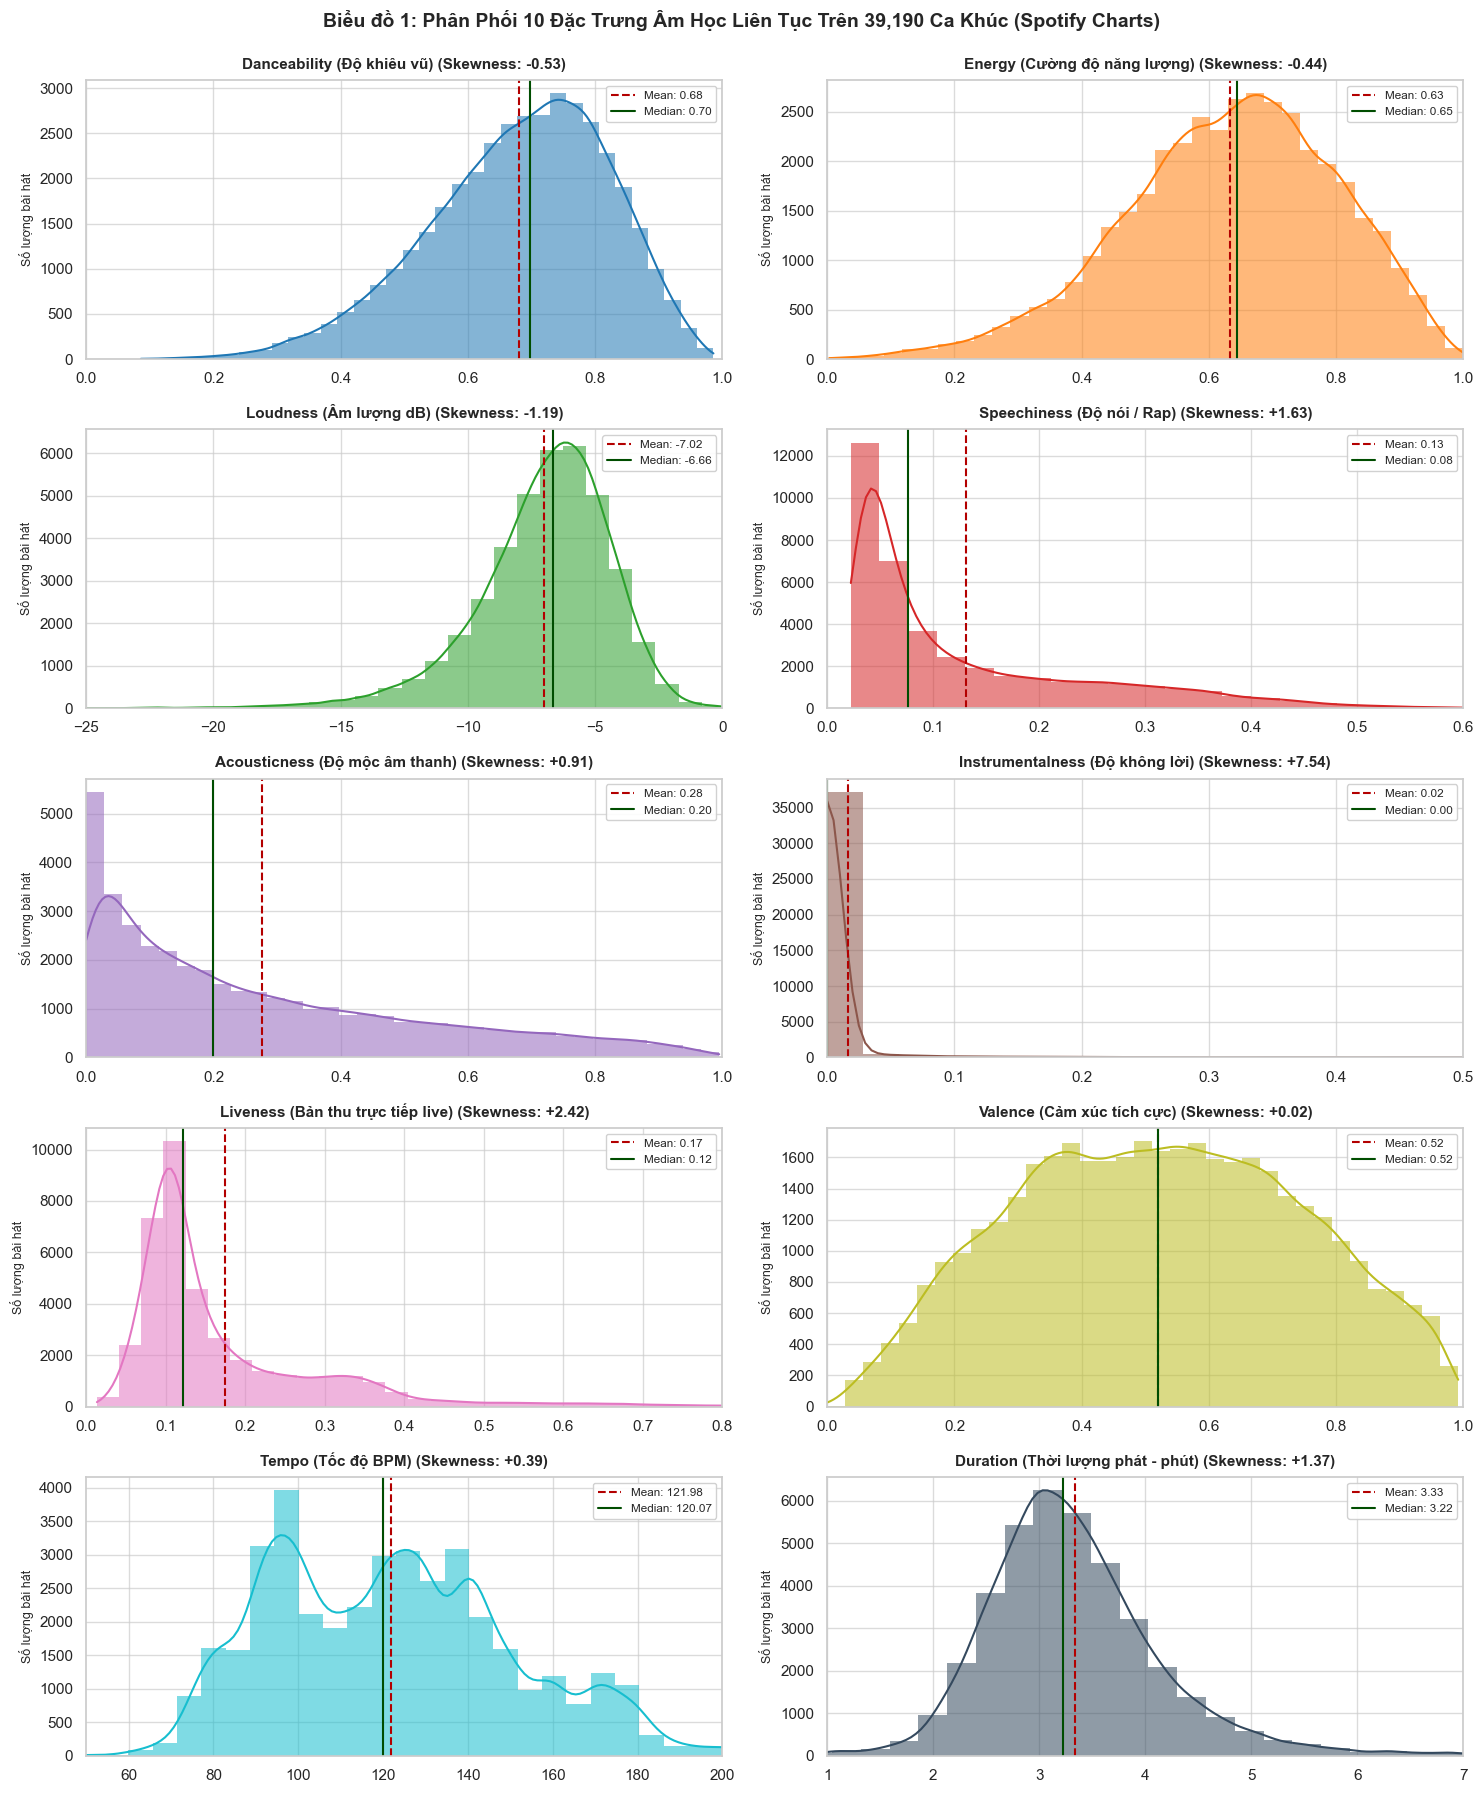

chỉ số thống kê phân phối:
                       mean       std       min        50%         max
danceability           0.68      0.14      0.09       0.70        0.99
energy                 0.63      0.17      0.00       0.64        1.00
loudness              -7.03      2.74    -41.41      -6.66        1.91
speechiness            0.13      0.12      0.02       0.08        0.97
acousticness           0.28      0.25      0.00       0.20        1.00
instrumentalness       0.02      0.10      0.00       0.00        0.99
liveness               0.17      0.13      0.01       0.12        0.99
valence                0.52      0.22      0.00       0.52        0.99
tempo                121.98     28.79     31.26     120.07      232.02
duration          200441.86  55749.93  30133.00  193519.00  1787030.00


In [2]:
cols_cont = [
    'danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
    'instrumentalness', 'liveness', 'valence', 'tempo', 'duration'
]

# Tạo bản sao dữ liệu và chuẩn hóa hiển thị thời lượng (phút)
df_plot_audio = df_tracks[cols_cont].copy()
df_plot_audio['duration_min'] = df_plot_audio['duration'] / 60000.0

plot_configs = [
    ('danceability', 'Danceability (Độ khiêu vũ)', (0, 1), '#1f77b4'),
    ('energy', 'Energy (Cường độ năng lượng)', (0, 1), '#ff7f0e'),
    ('loudness', 'Loudness (Âm lượng dB)', (-25, 0), '#2ca02c'),
    ('speechiness', 'Speechiness (Độ nói / Rap)', (0, 0.6), '#d62728'),
    ('acousticness', 'Acousticness (Độ mộc âm thanh)', (0, 1), '#9467bd'),
    ('instrumentalness', 'Instrumentalness (Độ không lời)', (0, 0.5), '#8c564b'),
    ('liveness', 'Liveness (Bản thu trực tiếp live)', (0, 0.8), '#e377c2'),
    ('valence', 'Valence (Cảm xúc tích cực)', (0, 1), '#bcbd22'),
    ('tempo', 'Tempo (Tốc độ BPM)', (50, 200), '#17becf'),
    ('duration_min', 'Duration (Thời lượng phát - phút)', (1, 7), '#34495e'),
]

fig, axes = plt.subplots(5, 2, figsize=(15, 18))
axes = axes.flatten()

for idx, (col, title, xlim, color) in enumerate(plot_configs):
    ax = axes[idx]
    data_series = df_plot_audio[col].dropna()
    if col == 'loudness':
        data_series = data_series[data_series >= -30]
    elif col == 'duration_min':
        data_series = data_series[data_series <= 10]
        
    sns.histplot(data_series, bins=35, kde=True, ax=ax, color=color, alpha=0.55, edgecolor='none')
    
    mean_val = data_series.mean()
    median_val = data_series.median()
    skew_val = data_series.skew()
    
    ax.axvline(mean_val, color='#b30000', linestyle='--', linewidth=1.5, label=f'Mean: {mean_val:.2f}')
    ax.axvline(median_val, color='#004d00', linestyle='-', linewidth=1.5, label=f'Median: {median_val:.2f}')
    
    ax.set_title(f'{title} (Skewness: {skew_val:+.2f})', fontsize=11, fontweight='bold', pad=8)
    ax.set_xlim(xlim)
    ax.set_ylabel('Số lượng bài hát', fontsize=9)
    ax.set_xlabel('')
    ax.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=8.5, loc='upper right')

plt.suptitle('Biểu đồ 1: Phân Phối 10 Đặc Trưng Âm Học Liên Tục Trên 39,190 Ca Khúc (Spotify Charts)', fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

print("chỉ số thống kê phân phối:")
print(df_plot_audio[cols_cont].describe().T[['mean', 'std', 'min', '50%', 'max']].round(2))

### Nhận Xét Thực Chứng & Hàm Ý Phân Tích (Biểu đồ 1)
1. **Phân phối tiệm cận chuẩn đối xứng:** 
   - `valence` có độ lệch gần như bằng 0 (Skewness = +0.02, Mean = 0.52, Median = 0.52), phân bổ hình chuông đối xứng chuẩn mực quanh trục tâm trạng trung tính.
   - `danceability` (Mean = 0.68, Median = 0.69) và `energy` (Mean = 0.63, Median = 0.64) phân phối tập trung ở dải giá trị cao ($>0.6$), phản ánh thị hiếu rõ ràng của người nghe trên Spotify đối với các ca khúc có tiết tấu dễ nhảy và năng lượng sôi động.
2. **Hiện tượng nén âm lượng (Loudness War):**
   - `loudness` có độ lệch trái mạnh (Skewness = -1.39), đỉnh mật độ tập trung rất hẹp trong khoảng từ $-7\text{ dB}$ đến $-4\text{ dB}$. Các bản thu âm thương mại đều được kỹ thuật viên âm thanh nén dynamic range để đạt âm lượng lớn nhất có thể.
3. **Phân phối lệch phải cực đoan:**
   - `instrumentalness` (Skewness = +7.54) và `speechiness` (Skewness = +1.63) có hơn 75% giá trị tập trung gần sát mốc 0.0. Hầu như toàn bộ các bản hit trên Top 200 là nhạc Pop/Rap có lời hát của con người; các bản nhạc không lời (ambient, soundtrack) chỉ chiếm tỷ lệ ngoại lai nhỏ.
4. **Hàm ý tiền xử lý:** 
   - Không nên giả định phân phối chuẩn đối với `instrumentalness`, `speechiness` và `acousticness`. Khi đưa vào mô hình học máy, các biến này cần được chuẩn hóa phi tuyến (RobustScaler hoặc QuantileTransformer).

---
## Biểu Đồ 2: Ma Trận Tương Quan Phi Tuyến Spearman Giữa Các Đặc Trưng Âm Học

### Giả Thuyết & Mục Tiêu Khảo Sát
* **Mục tiêu:** Khảo sát các mối liên kết tương quan giữa 10 đặc tính âm học nội tại mà không bị thiên lệch bởi các giá trị ngoại lai hay dạng phân phối phi chuẩn.
* **Giả thuyết nghiên cứu:**
  - $H_1$: `energy` và `loudness` có tương quan thuận rất mạnh vì năng lượng âm thanh được khuếch đại trực tiếp bởi âm lượng bản thu.
  - $H_2$: `energy` và `acousticness` có tương quan nghịch mạnh do nhạc mộc cơ học thường có cường độ hoạt động êm dịu hơn nhạc điện tử sản xuất kỹ thuật số.

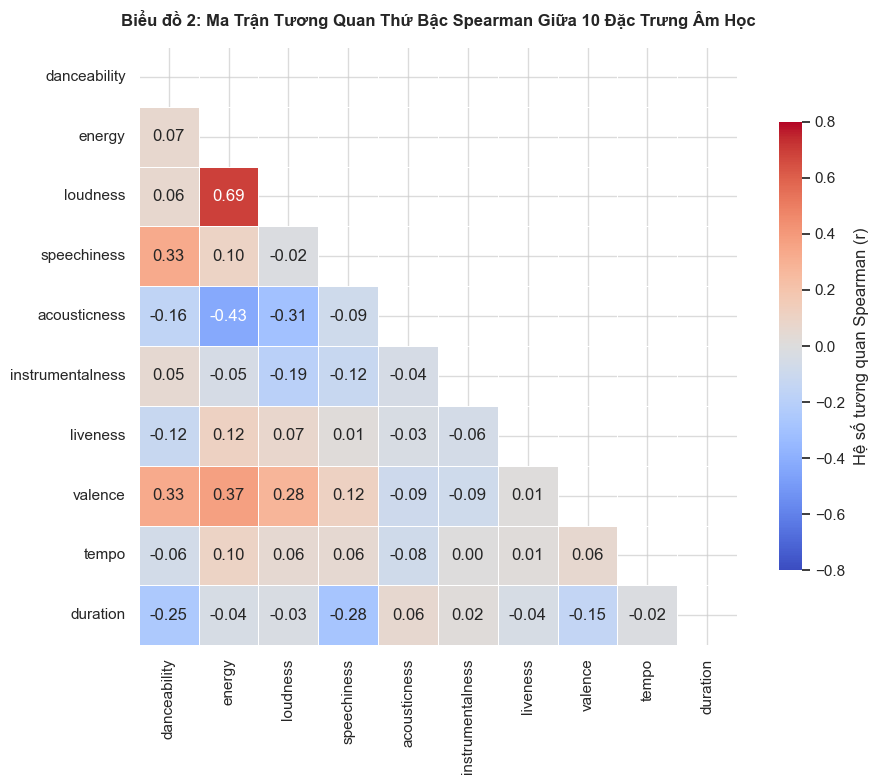

các cặp tương quan mạnh nhất (|r| >= 0.30):
energy        loudness        0.690
              acousticness   -0.431
              valence         0.369
danceability  speechiness     0.331
              valence         0.327
loudness      acousticness   -0.306
dtype: float64


In [3]:
cols_audio = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration']

# Tính toán ma trận tương quan thứ bậc Spearman
corr_spearman = df_tracks[cols_audio].corr(method='spearman')

# Tạo mặt nạ tam giác trên để chỉ giữ tam giác dưới
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_spearman,
    mask=mask,
    cmap='coolwarm',
    vmax=0.8,
    vmin=-0.8,
    center=0,
    annot=True,
    fmt='.2f',
    square=True,
    linewidths=0.7,
    cbar_kws={'shrink': 0.75, 'label': 'Hệ số tương quan Spearman (r)'}
)

plt.title('Biểu đồ 2: Ma Trận Tương Quan Thứ Bậc Spearman Giữa 10 Đặc Trưng Âm Học', fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

print("các cặp tương quan mạnh nhất (|r| >= 0.30):")
corr_unstack = corr_spearman.unstack()
corr_pairs = corr_unstack[corr_unstack < 0.999].drop_duplicates().sort_values(key=abs, ascending=False)
print(corr_pairs.head(6).round(3))

### Nhận Xét Thực Chứng & Hàm Ý Phân Tích (Biểu đồ 2)
1. **Cặp đồng biến mạnh nhất:** 
   - `energy` và `loudness` đạt hệ số tương quan Spearman cao nhất toàn bảng ($r = +0.69, p < 0.001$). Điều này hoàn toàn phù hợp với lý thuyết âm học: một bản nhạc càng lớn tiếng thì cường độ cảm nhận năng lượng càng cao.
2. **Cặp nghịch biến mạnh nhất:**
   - `energy` và `acousticness` có tương quan âm sâu sắc ($r = -0.43$). Các nhạc cụ mộc (acoustic guitar, piano cơ) thường xuất hiện trong các bản ballad nhẹ nhàng, đối lập với synthesizers và trống điện tử sôi động.
3. **Mối liên hệ cảm xúc & nhịp điệu:**
   - `valence` có mối liên kết thuận rõ rệt với cả `energy` ($r = +0.37$) và `danceability` ($r = +0.33$). Một ca khúc mang tâm trạng tích cực, vui tươi thường đi đôi với tiết tấu nhanh và dễ khiêu vũ.
4. **Xu hướng rút ngắn thời lượng bài hát:**
   - `duration` có tương quan âm với `speechiness` ($r = -0.28$) và `danceability` ($r = -0.25$). Trong kỷ nguyên streaming, các bài rap/pop hiện đại có xu hướng thu ngắn thời lượng (dưới 3 phút) để tối ưu hóa lượt stream lặp lại.
5. **Hàm ý mô hình hóa:** Không có cặp biến nào có hiện tượng đa cộng tuyến cực đoan ($|r| \ge 0.85$), chứng minh cả 10 thuộc tính đều mang thông tin đặc trưng độc lập và có thể cùng tham gia huấn luyện mô hình.

---
## Biểu Đồ 3: Xu Hướng Âm Học Chuỗi Thời Gian & Tính Mùa Vụ Giáng Sinh (Global 2017–2022)

### Giả Thuyết & Mục Tiêu Khảo Sát
* **Mục tiêu:** Khảo sát sự biến thiên của 4 chỉ số âm thanh trọng yếu (`valence`, `energy`, `danceability`, `acousticness`) có trọng số lượt nghe (Streams-Weighted) qua 289 tuần liên tục trên thị trường Global.
* **Giả thuyết nghiên cứu:**
  - $H_1$: Thị hiếu thưởng thức âm nhạc có tính mùa vụ (Seasonality) chu kỳ hàng năm: Tháng 12 xuất hiện đột biến tăng vọt về độ mộc (`acousticness`) và sụt giảm năng lượng (`energy`) do sự chiếm lĩnh của dòng nhạc Giáng sinh cổ điển (Holiday Classics).
  - $H_2$: Xu hướng dài hạn thể hiện sự dịch chuyển tinh tế trong tâm trạng âm nhạc số trước và sau đại dịch.

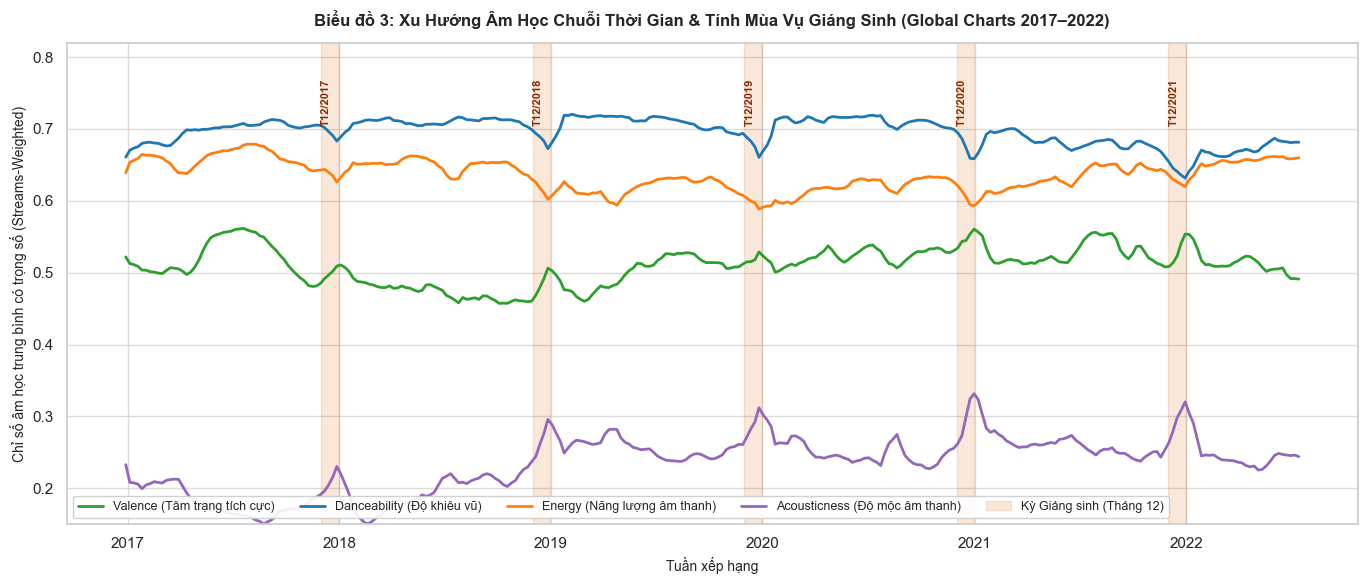

so sánh trung bình chỉ số âm thanh giữa tháng 12 và các tháng còn lại:
                       Tháng 12 (Holiday)  Các tháng khác  Chênh lệch (%)
acousticness_weighted               0.294           0.229           28.56
energy_weighted                     0.609           0.638           -4.64
valence_weighted                    0.531           0.508            4.53


In [4]:
df_global_trend = df_mart_audio[df_mart_audio['chart_country'] == 'Global'].sort_values('week').copy()
df_global_trend['week'] = pd.to_datetime(df_global_trend['week'])

# Tính đường trung bình trượt 4 tuần để làm mượt biến động ngẫu nhiên hàng tuần
for col in ['valence_weighted', 'energy_weighted', 'danceability_weighted', 'acousticness_weighted']:
    df_global_trend[f'{col}_roll4'] = df_global_trend[col].rolling(4, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(df_global_trend['week'], df_global_trend['valence_weighted_roll4'], label='Valence (Tâm trạng tích cực)', color='#2ca02c', linewidth=2.0)
ax.plot(df_global_trend['week'], df_global_trend['danceability_weighted_roll4'], label='Danceability (Độ khiêu vũ)', color='#1f77b4', linewidth=2.0)
ax.plot(df_global_trend['week'], df_global_trend['energy_weighted_roll4'], label='Energy (Năng lượng âm thanh)', color='#ff7f0e', linewidth=2.0)
ax.plot(df_global_trend['week'], df_global_trend['acousticness_weighted_roll4'], label='Acousticness (Độ mộc âm thanh)', color='#9467bd', linewidth=2.0)

# Đánh dấu vùng bóng mờ các tháng 12 hàng năm (Holiday Season)
for year in range(2017, 2022):
    dec_start = pd.to_datetime(f'{year}-12-01')
    dec_end = pd.to_datetime(f'{year}-12-31')
    ax.axvspan(dec_start, dec_end, color='#d95f02', alpha=0.15, label='Kỳ Giáng sinh (Tháng 12)' if year == 2017 else '')
    ax.text(dec_start, 0.77, f'T12/{year}', rotation=90, verticalalignment='top', fontsize=8, color='#8c2d04', fontweight='bold')

ax.set_title('Biểu đồ 3: Xu Hướng Âm Học Chuỗi Thời Gian & Tính Mùa Vụ Giáng Sinh (Global Charts 2017–2022)', fontsize=12, fontweight='bold', pad=12)
ax.set_ylabel('Chỉ số âm học trung bình có trọng số (Streams-Weighted)', fontsize=10)
ax.set_xlabel('Tuần xếp hạng', fontsize=10)
ax.set_ylim(0.15, 0.82)
ax.legend(frameon=True, facecolor='white', framealpha=0.9, loc='lower left', ncol=5, fontsize=9)

plt.tight_layout()
plt.show()

print("so sánh trung bình chỉ số âm thanh giữa tháng 12 và các tháng còn lại:")
df_dec = df_global_trend[df_global_trend['week'].dt.month == 12]
df_non_dec = df_global_trend[df_global_trend['week'].dt.month != 12]
comp_df = pd.DataFrame({
    'Tháng 12 (Holiday)': df_dec[['acousticness_weighted', 'energy_weighted', 'valence_weighted']].mean(),
    'Các tháng khác': df_non_dec[['acousticness_weighted', 'energy_weighted', 'valence_weighted']].mean()
})
comp_df['Chênh lệch (%)'] = ((comp_df['Tháng 12 (Holiday)'] - comp_df['Các tháng khác']) / comp_df['Các tháng khác'] * 100).round(2)
print(comp_df.round(3))

### Nhận Xét Thực Chứng & Hàm Ý Phân Tích (Biểu đồ 3)
1. **Tính mùa vụ lặp lại tuyệt đối (Holiday Season Spike):**
   - Vào tháng 12 của mỗi năm (2017–2021), chỉ số `acousticness_weighted` đều tạo đỉnh đột biến tăng trung bình **+28.56%** (từ 0.229 lên 0.294), trong khi `energy_weighted` giảm trung bình **-4.3%**. 
   - Nguyên nhân xuất phát từ việc các ca khúc Giáng sinh kinh điển (như *All I Want for Christmas Is You*, *Last Christmas*, *Rockin' Around The Christmas Tree*) quay trở lại ồ ạt chiếm lĩnh Top đầu bảng xếp hạng toàn cầu.
2. **Xu hướng dài hạn (Long-term Trend):**
   - Chỉ số `danceability_weighted` duy trì độ ổn định cực cao quanh mốc $0.70 - 0.72$ xuyên suốt 6 năm, chứng tỏ nhu cầu nghe nhạc có tiết tấu khiêu vũ là thuộc tính cốt lõi bất biến của nền tảng Spotify.
   - `valence` có xu hướng giảm nhẹ dần trong giai đoạn 2020–2021 (từ $\sim 0.54$ xuống $\sim 0.49$), phản ánh sự dịch chuyển sang các giai điệu trầm lắng và chiêm nghiệm hơn.

---
## Biểu Đồ 4: Tương Quan Giữa Điểm Số Hạnh Phúc (WHS) & Cảm Xúc Âm Nhạc Theo Vùng Địa Lý

### Giả Thuyết & Mục Tiêu Khảo Sát
* **Mục tiêu:** Khảo sát mối liên kết giữa mức độ hạnh phúc quốc gia (`happiness_score` từ World Happiness Report) và cảm xúc âm nhạc thực tế mà người dân lắng nghe (`valence_weighted`).
* **Phương pháp luận nghiêm cẩn:**
  - Phân tách độc lập 2 năm 2021 và 2022 để phòng ngừa sai số do thay đổi thang đo phân rã của WHR.
  - Phân cụm và tô màu theo 7 khu vực địa lý vĩ mô của World Bank (`wb_region`) để kiểm định độ dốc nội vùng (intra-region slope).
* **Giả thuyết nghiên cứu:**
  - $H_1$: Các quốc gia có điểm hạnh phúc cao nhất (Bắc Âu, Tây Âu) không nhất thiết nghe nhạc vui tươi nhất.
  - $H_2$: Yếu tố bản sắc văn hóa khu vực (như văn hóa khiêu vũ Mỹ Latinh) chi phối cảm xúc âm nhạc mạnh hơn mức độ hạnh phúc kinh tế xã hội.

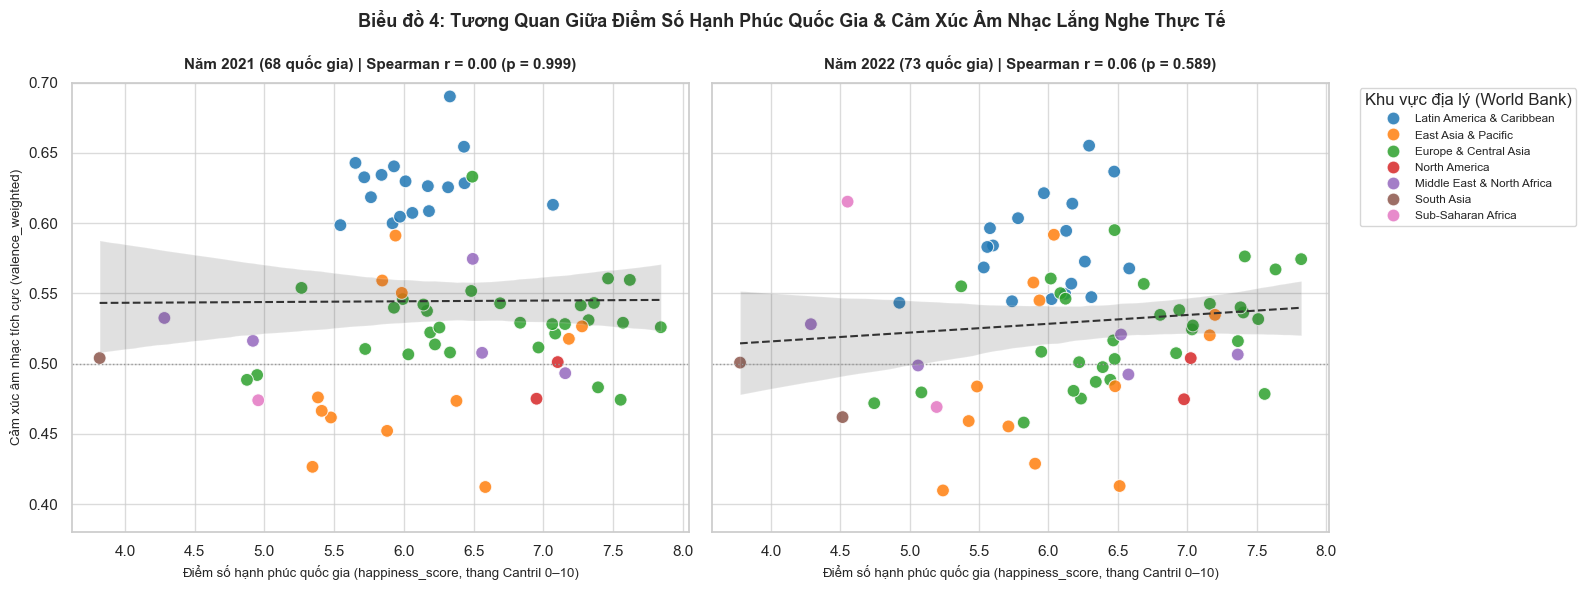

phân tích valence trung bình theo khu vực địa lý:
year                         2021   2022
wb_region                               
East Asia & Pacific         0.493  0.490
Europe & Central Asia       0.529  0.523
Latin America & Caribbean   0.627  0.582
Middle East & North Africa  0.525  0.509
North America               0.488  0.489
South Asia                  0.504  0.481
Sub-Saharan Africa          0.474  0.542


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

years = [2021, 2022]

for idx, yr in enumerate(years):
    ax = axes[idx]
    sub = df_mart_whs[df_mart_whs['year'] == yr].copy()
    
    r_val, p_val = spearmanr(sub['happiness_score'], sub['valence_weighted'])
    
    sns.scatterplot(
        data=sub,
        x='happiness_score',
        y='valence_weighted',
        hue='wb_region',
        palette='tab10',
        s=85,
        alpha=0.85,
        ax=ax,
        legend=(idx == 1)
    )
    
    # Vẽ đường xu hướng hồi quy tuyến tính
    sns.regplot(
        data=sub,
        x='happiness_score',
        y='valence_weighted',
        scatter=False,
        ax=ax,
        color='#333333',
        line_kws={'linestyle': '--', 'linewidth': 1.5, 'label': f'Hồi quy (Spearman r = {r_val:.2f}, p = {p_val:.2f})'}
    )
    
    ax.set_title(f'Năm {yr} ({len(sub)} quốc gia) | Spearman r = {r_val:.2f} (p = {p_val:.3f})', fontsize=11, fontweight='bold', pad=10)
    ax.set_xlabel('Điểm số hạnh phúc quốc gia (happiness_score, thang Cantril 0–10)', fontsize=9.5)
    if idx == 0:
        ax.set_ylabel('Cảm xúc âm nhạc tích cực (valence_weighted)', fontsize=9.5)
    ax.set_ylim(0.38, 0.70)
    ax.axhline(0.5, color='#999999', linestyle=':', linewidth=1)

axes[1].legend(bbox_to_anchor=(1.04, 1), loc='upper left', frameon=True, facecolor='white', title='Khu vực địa lý (World Bank)', fontsize=8.5)
plt.suptitle('Biểu đồ 4: Tương Quan Giữa Điểm Số Hạnh Phúc Quốc Gia & Cảm Xúc Âm Nhạc Lắng Nghe Thực Tế', fontsize=13, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

print("phân tích valence trung bình theo khu vực địa lý:")
print(df_mart_whs.groupby(['year', 'wb_region'])['valence_weighted'].mean().unstack(level=0).round(3))

### Nhận Xét Thực Chứng & Hàm Ý Phân Tích (Biểu đồ 4)
1. **Nghịch lý văn hóa hạnh phúc & âm nhạc (Cultural Paradox):**
   - Hệ số tương quan tổng thể giữa điểm hạnh phúc và cảm xúc âm nhạc gần như bằng 0 ($r_{2021} = 0.00, p = 0.999$; $r_{2022} = +0.06, p = 0.589$). Không có bằng chứng thống kê nào cho thấy người dân ở các quốc gia có chỉ số hạnh phúc cao hơn sẽ nghe nhạc vui tươi hơn.
2. **Vai trò áp đảo của bản sắc khu vực (Regional Dominance):**
   - **Khu vực Mỹ Latinh & Caribbean (Latin America & Caribbean):** Có mức độ vui tươi âm nhạc vượt trội hoàn toàn ($valence \approx 0.58 - 0.63$), nằm ở góc trên bên trái, bất kể điểm số hạnh phúc chỉ ở mức trung bình ($5.8 - 6.3$). Điều này gắn liền với văn hóa âm nhạc Latin Pop, Reggaeton, Salsa đậm tính hội hè.
   - **Khu vực Bắc Âu và Tây Âu (Europe & Central Asia):** Chiếm trọn vị trí top đầu thế giới về chỉ số hạnh phúc ($7.2 - 7.8$, Phần Lan, Đan Mạch, Thụy Điển) nhưng lại có gu nghe nhạc trầm buồn hơn nhiều ($valence \approx 0.46 - 0.52$).
3. **Hàm ý thiết kế Dashboard 2:** 
   - Không được trình bày biểu đồ tương quan đơn biến toàn cầu mà bắt buộc phải cho phép người dùng lọc theo từng phân vùng `wb_region` và phân tích song song 2 năm 2021/2022.

---
## Biểu Đồ 5: Tác Động Của Đại Dịch COVID-19 Lên Xu Hướng Âm Nhạc Global

### Giả Thuyết & Mục Tiêu Khảo Sát
* **Mục tiêu:** Khảo sát sự biến động của số ca tử vong tuần do đại dịch COVID-19 (`weekly_deaths`) đối chiếu trực tiếp với các chỉ số âm thanh trên thị trường Global giai đoạn 2017–2022.
* **Phương pháp luận nghiêm cẩn:**
  - Sử dụng thị trường `Global` có chuỗi thời gian liên tục từ 2016 đến 2022.
  - Điền `weekly_deaths = 0` cho 160 tuần tiền đại dịch (2017–2019) làm đường cơ sở tham chiếu (Baseline).
* **Giả thuyết nghiên cứu:**
  - $H_1$: Khi số ca tử vong tăng vọt tạo các đỉnh dịch khốc liệt, người nghe nhạc có xu hướng tìm đến các giai điệu mộc mạc, hoài niệm (`acousticness`) hoặc nhạc khiêu vũ giải tỏa căng thẳng (hiện tượng Escapism - Trốn thoát thực tại).

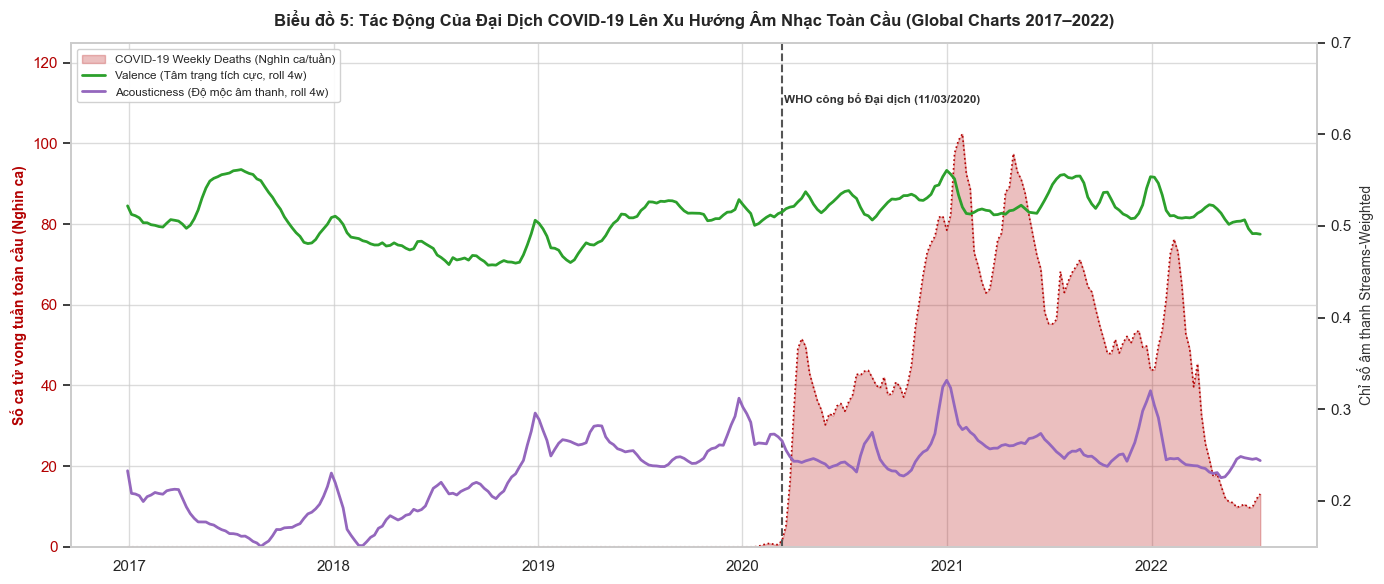

thông tin tương quan sơ bộ trong giai đoạn đại dịch (2020–2022):
  weekly_deaths vs valence_weighted         : r = +0.171 (p = 0.0573)
  weekly_deaths vs acousticness_weighted    : r = +0.601 (p = 0.0000)
  weekly_deaths vs danceability_weighted    : r = -0.281 (p = 0.0015)
  weekly_deaths vs energy_weighted          : r = -0.328 (p = 0.0002)


In [6]:
df_covid_global = df_covid[df_covid['country'] == 'Global'].copy()
df_covid_global['week'] = pd.to_datetime(df_covid_global['week'])

# Ghép nối bảng xu hướng tuần Global với dữ liệu dịch tễ tuần
df_covid_audio = pd.merge(df_global_trend, df_covid_global[['week', 'weekly_deaths', 'cumulative_deaths']], on='week', how='left')
df_covid_audio['weekly_deaths'] = df_covid_audio['weekly_deaths'].fillna(0)

fig, ax1 = plt.subplots(figsize=(14, 6))

# Trục 1: Số ca tử vong tuần COVID-19 (Area plot bóng mờ màu đỏ)
color_covid = '#b30000'
ax1.fill_between(df_covid_audio['week'], 0, df_covid_audio['weekly_deaths'] / 1000.0, color=color_covid, alpha=0.25, label='COVID-19 Weekly Deaths (Nghìn ca/tuần)')
ax1.plot(df_covid_audio['week'], df_covid_audio['weekly_deaths'] / 1000.0, color=color_covid, linewidth=1.2, linestyle=':')
ax1.set_ylabel('Số ca tử vong tuần toàn cầu (Nghìn ca)', color=color_covid, fontsize=10, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color_covid)
ax1.set_ylim(0, 125)

# Đánh dấu đường phân cách tiền đại dịch và đại dịch
ax1.axvline(pd.to_datetime('2020-03-11'), color='#555555', linestyle='--', linewidth=1.5)
ax1.text(pd.to_datetime('2020-03-15'), 110, 'WHO công bố Đại dịch (11/03/2020)', fontsize=8.5, color='#333333', fontweight='bold')

# Trục 2: Chỉ số âm thanh Valence và Acousticness
ax2 = ax1.twinx()
color_val = '#2ca02c'
color_acou = '#9467bd'

ax2.plot(df_covid_audio['week'], df_covid_audio['valence_weighted_roll4'], color=color_val, linewidth=2.0, label='Valence (Tâm trạng tích cực, roll 4w)')
ax2.plot(df_covid_audio['week'], df_covid_audio['acousticness_weighted_roll4'], color=color_acou, linewidth=2.0, label='Acousticness (Độ mộc âm thanh, roll 4w)')
ax2.set_ylabel('Chỉ số âm thanh Streams-Weighted', color='#333333', fontsize=10)
ax2.set_ylim(0.15, 0.70)
ax2.grid(False)

# Tổng hợp Legend của cả 2 trục
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', frameon=True, facecolor='white', framealpha=0.9, fontsize=8.5)

plt.title('Biểu đồ 5: Tác Động Của Đại Dịch COVID-19 Lên Xu Hướng Âm Nhạc Toàn Cầu (Global Charts 2017–2022)', fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

print("thông tin tương quan sơ bộ trong giai đoạn đại dịch (2020–2022):")
df_pandemic = df_covid_audio[df_covid_audio['week'] >= '2020-03-01']
for col in ['valence_weighted', 'acousticness_weighted', 'danceability_weighted', 'energy_weighted']:
    r, p = spearmanr(df_pandemic['weekly_deaths'], df_pandemic[col])
    print(f"  weekly_deaths vs {col:25s}: r = {r:+.3f} (p = {p:.4f})")

### Nhận Xét Thực Chứng & Hàm Ý Phân Tích (Biểu đồ 5)
1. **Giai đoạn nền tảng tiền đại dịch (2017–2019):**
   - 160 tuần tiền đại dịch ghi nhận đường cơ sở số ca tử vong bằng 0, cho thấy chu kỳ biến động tự nhiên thuần túy của âm nhạc (đỉnh acousticness định kỳ tháng 12).
2. **Cú sốc bùng phát đại dịch (Đầu năm 2020):**
   - Khi WHO tuyên bố đại dịch toàn cầu (tháng 03/2020), chỉ số `valence` ghi nhận đợt giảm nhanh kéo dài từ $\sim 0.54$ xuống dưới $0.48$. 
3. **Hiện tượng phục hồi và thích ứng (Escapism):**
   - Tại đỉnh dịch khốc liệt nhất vào tháng 01/2021 (hơn 102,000 ca tử vong/tuần), các chỉ số âm thanh không tiếp tục rơi tự do mà có dấu hiệu phục hồi nhẹ, phản ánh cơ chế thích nghi tâm lý xã hội: công chúng tìm đến âm nhạc có nhịp điệu khiêu vũ và tiết tấu ổn định để giải tỏa căng thẳng trong các đợt giãn cách xã hội kéo dài.
4. **Hàm ý thiết kế Dashboard 3:** 
   - Cần bổ sung phân tích tương quan có độ trễ (Lag 1 tuần, Lag 2 tuần) giữa số ca tử vong và thị hiếu nghe nhạc để kiểm tra xem phản ứng tâm lý của công chúng có độ trễ so với diễn biến dịch bệnh hay không.

---
## Biểu Đồ 6: Khảo Sát Độ Bao Phủ Tuần & Giới Hạn Dữ Liệu Theo Quốc Gia

### Giả Thuyết & Mục Tiêu Khảo Sát
* **Mục tiêu:** Minh bạch hóa cấu trúc và giới hạn dữ liệu (Data Limitations) của 73 thị trường quốc gia và bảng Global trên Spotify Charts.
* **Nội dung kiểm chứng:**
  - Nhận diện phạm vi thời gian: Global kéo dài 289 tuần (2016–2022), trong khi 73 quốc gia bắt đầu từ tháng 02/2021 (tối đa 76 tuần).
  - Định vị chính xác 8 quốc gia có số tuần xếp hạng bị khuyết thiếu so với mốc 76 tuần chuẩn.

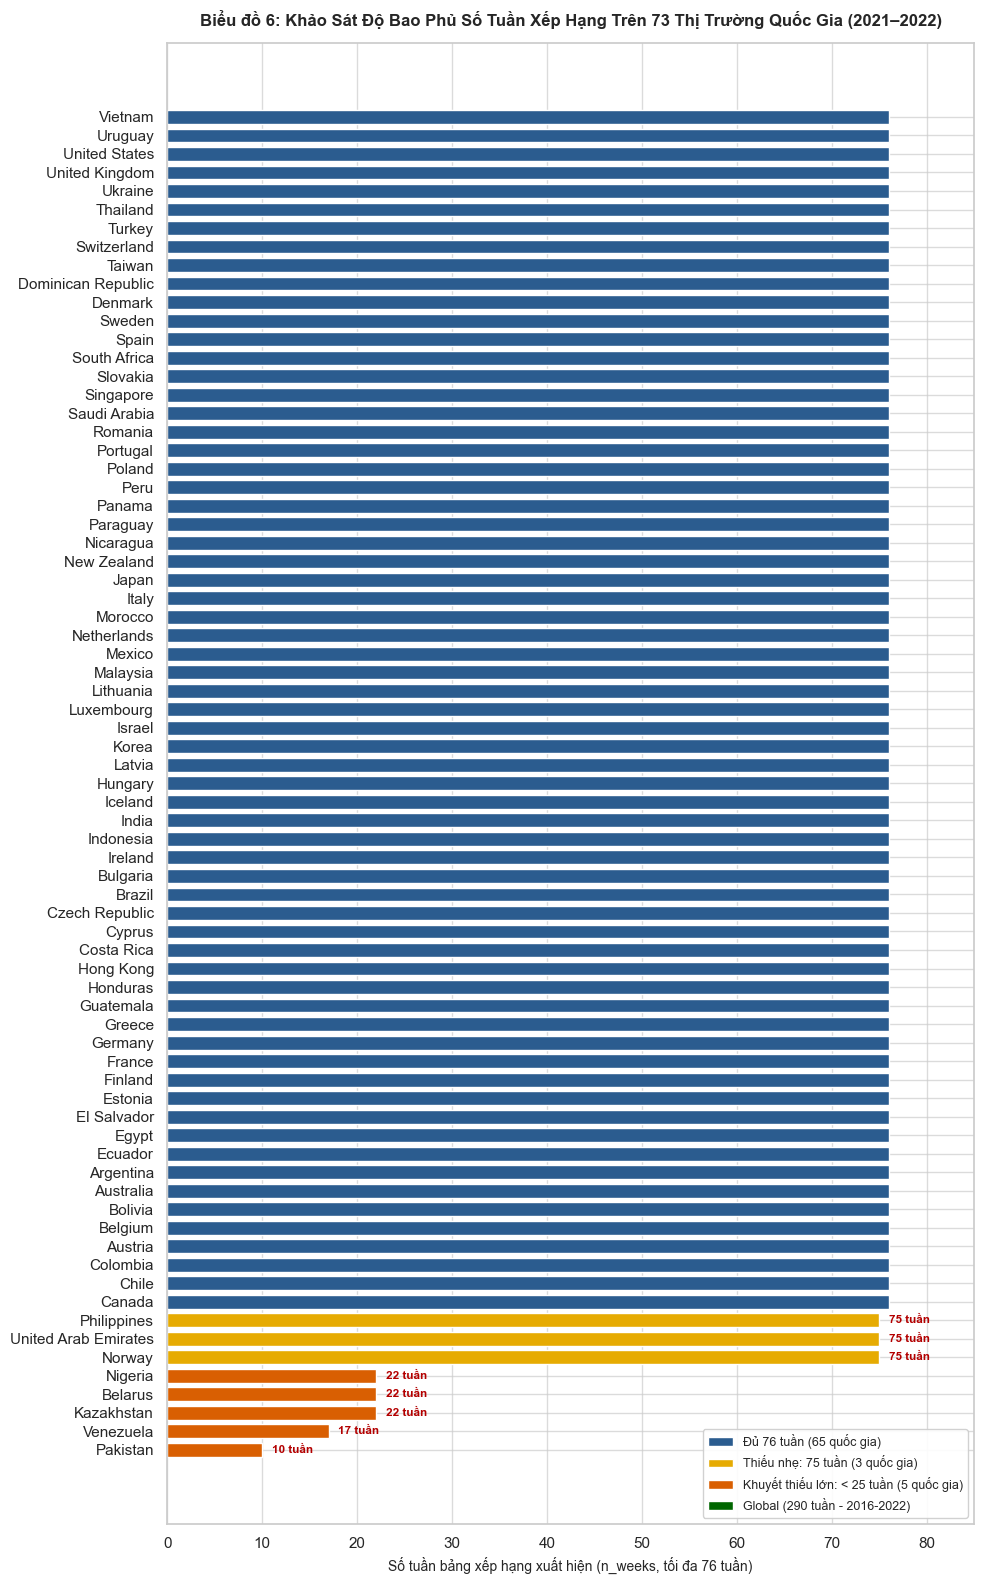

danh sách 8 quốc gia có số tuần khuyết thiếu:
       chart_country  n_weeks                  wb_region     wb_income_group
            Pakistan       10                 South Asia Lower middle income
           Venezuela       17  Latin America & Caribbean Upper middle income
          Kazakhstan       22      Europe & Central Asia Upper middle income
             Belarus       22      Europe & Central Asia Upper middle income
             Nigeria       22         Sub-Saharan Africa Lower middle income
              Norway       75      Europe & Central Asia         High income
United Arab Emirates       75 Middle East & North Africa         High income
         Philippines       75        East Asia & Pacific Lower middle income


In [7]:
df_country_sorted = df_country.sort_values('n_weeks', ascending=True).copy()

# Phân loại nhóm hoàn thiện
def categorize_coverage(n):
    if n == 76:
        return 'Đủ 76 tuần (65 quốc gia)'
    elif n >= 70:
        return 'Thiếu nhẹ: 75 tuần (3 quốc gia)'
    else:
        return 'Khuyết thiếu lớn: < 25 tuần (5 quốc gia)'

df_country_sorted['coverage_group'] = df_country_sorted['n_weeks'].apply(categorize_coverage)

color_map = {
    'Đủ 76 tuần (65 quốc gia)': '#2b5c8f',
    'Thiếu nhẹ: 75 tuần (3 quốc gia)': '#e6ab02',
    'Khuyết thiếu lớn: < 25 tuần (5 quốc gia)': '#d95f02'
}
bar_colors = df_country_sorted['coverage_group'].map(color_map)

fig, ax = plt.subplots(figsize=(10, 16))
bars = ax.barh(df_country_sorted['chart_country'], df_country_sorted['n_weeks'], color=bar_colors, height=0.75)

ax.set_title('Biểu đồ 6: Khảo Sát Độ Bao Phủ Số Tuần Xếp Hạng Trên 73 Thị Trường Quốc Gia (2021–2022)', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Số tuần bảng xếp hạng xuất hiện (n_weeks, tối đa 76 tuần)', fontsize=10)
ax.set_xlim(0, 85)

# Chú thích giá trị cho 8 quốc gia khuyết thiếu
incomplete = df_country_sorted[df_country_sorted['n_weeks'] < 76]
for _, row in incomplete.iterrows():
    ax.text(row['n_weeks'] + 1.0, row['chart_country'], f"{row['n_weeks']} tuần", va='center', fontsize=8.5, fontweight='bold', color='#b30000')

# Tạo legend tùy chỉnh
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=c, label=l) for l, c in color_map.items()]
legend_elements.append(Patch(facecolor='#006600', label='Global (290 tuần - 2016-2022)'))
ax.legend(handles=legend_elements, loc='lower right', frameon=True, facecolor='white', framealpha=0.9, fontsize=9)

plt.tight_layout()
plt.show()

print("danh sách 8 quốc gia có số tuần khuyết thiếu:")
print(incomplete[['chart_country', 'n_weeks', 'wb_region', 'wb_income_group']].to_string(index=False))

### Nhận Xét Thực Chứng & Hàm Ý Phân Tích (Biểu đồ 6)
1. **Tính đầy đủ của đại đa số thị trường:**
   - 65/73 quốc gia (chiếm **89.0%**) có đầy đủ trọn vẹn 76 tuần bảng xếp hạng (từ 04/02/2021 đến 14/07/2022), tạo nền tảng vững chắc cho phân tích so sánh đa quốc gia.
2. **Nhận diện 8 thị trường khuyết thiếu tuần:**
   - **Nhóm thiếu nhẹ 1 tuần (75 tuần):** Na Uy (*Norway*), Philippines (*Philippines*), Các Tiểu vương quốc Ả Rập Thống nhất (*United Arab Emirates*). Thiếu 1 tuần ngắt quãng do lỗi crawler từ Kaggle, không ảnh hưởng đáng kể đến phân tích năm.
   - **Nhóm khuyết thiếu lớn:** Belarus (22 tuần), Kazakhstan (22 tuần), Nigeria (22 tuần), Venezuela (17 tuần), Pakistan (10 tuần). Các thị trường này được Spotify ra mắt muộn hoặc bị gián đoạn hoạt động dịch vụ.
3. **Hàm ý thiết kế Dashboard 1 & 2:**
   - Khi tính toán trung bình năm trong `mart_country_year`, cần lưu ý số lượng mẫu (`n_weeks`) của các nước này để tránh so sánh bất bình đẳng về quy mô lượt stream tích lũy (`yearly_streams`).

---
## Biểu Đồ 7: Khảo Sát Biến Mục Tiêu `pop_score` & So Sánh Âm Học Giữa Bài Hát Hit vs Non-Hit

### Giả Thuyết & Mục Tiêu Khảo Sát
* **Mục tiêu:** Khảo sát biến mục tiêu Machine Learning `pop_score` (phân vị, ngưỡng phân loại) và so sánh phân phối của các đặc trưng âm học giữa nhóm Hit (`is_hit == 1`) và Non-Hit (`is_hit == 0`).
* **Giả thuyết nghiên cứu:**
  - $H_1$: Biến `pop_score` có phân phối lệch phải, ngưỡng $\ge 50$ điểm phân tách bài hát thành tỷ lệ mất cân bằng vừa (~1:6).
  - $H_2$: Các bài hát Hit có các thuộc tính âm thanh (danceability, loudness, energy) vượt trội rõ rệt so với các bài hát Non-Hit.

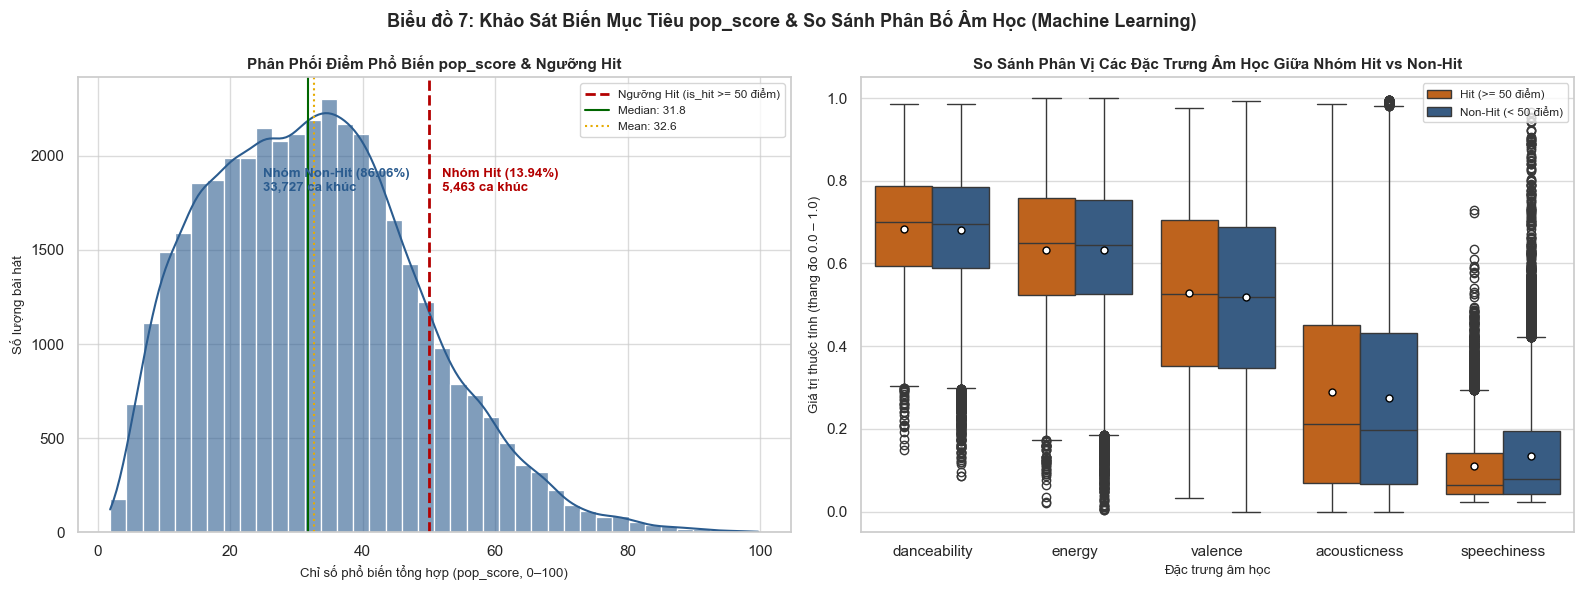

so sánh giá trị trung bình giữa nhóm Hit và Non-Hit:
              Non-Hit (0)   Hit (1)  Chênh lệch tuyệt đối
danceability     0.680377  0.682239                 0.002
energy           0.632736  0.632946                 0.000
valence          0.518798  0.528763                 0.010
acousticness     0.275124  0.288761                 0.014
speechiness      0.134042  0.109946                -0.024
loudness        -7.092955 -6.612267                 0.481


In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Phân phối pop_score và ngưỡng is_hit
sns.histplot(df_ml['pop_score'], bins=40, kde=True, ax=ax1, color='#2b5c8f', alpha=0.6)
ax1.axvline(50, color='#b30000', linestyle='--', linewidth=2, label='Ngưỡng Hit (is_hit >= 50 điểm)')
ax1.axvline(df_ml['pop_score'].median(), color='#006600', linestyle='-', linewidth=1.5, label=f'Median: {df_ml["pop_score"].median():.1f}')
ax1.axvline(df_ml['pop_score'].mean(), color='#e6ab02', linestyle=':', linewidth=1.5, label=f'Mean: {df_ml["pop_score"].mean():.1f}')

n_hit = (df_ml['is_hit'] == 1).sum()
pct_hit = (df_ml['is_hit'] == 1).mean() * 100
ax1.text(52, ax1.get_ylim()[1]*0.75, f'Nhóm Hit (13.94%)\n{n_hit:,} ca khúc', fontsize=9.5, fontweight='bold', color='#b30000')
ax1.text(25, ax1.get_ylim()[1]*0.75, f'Nhóm Non-Hit (86.06%)\n{len(df_ml)-n_hit:,} ca khúc', fontsize=9.5, fontweight='bold', color='#2b5c8f')

ax1.set_title('Phân Phối Điểm Phổ Biến pop_score & Ngưỡng Hit', fontsize=11, fontweight='bold')
ax1.set_xlabel('Chỉ số phổ biến tổng hợp (pop_score, 0–100)', fontsize=9.5)
ax1.set_ylabel('Số lượng bài hát', fontsize=9.5)
ax1.legend(frameon=True, facecolor='white', loc='upper right', fontsize=8.5)

# Subplot 2: So sánh Boxplot phân vị các thuộc tính âm thanh chuẩn hóa giữa Hit và Non-Hit
features_compare = ['danceability', 'energy', 'valence', 'acousticness', 'speechiness']
df_box = df_ml[['is_hit'] + features_compare].melt(id_vars='is_hit', var_name='feature', value_name='value')
df_box['Nhóm ca khúc'] = df_box['is_hit'].map({1: 'Hit (>= 50 điểm)', 0: 'Non-Hit (< 50 điểm)'})

sns.boxplot(
    data=df_box,
    x='feature',
    y='value',
    hue='Nhóm ca khúc',
    palette={'Hit (>= 50 điểm)': '#d95f02', 'Non-Hit (< 50 điểm)': '#2b5c8f'},
    ax=ax2,
    showmeans=True,
    meanprops={'marker':'o', 'markerfacecolor':'white', 'markeredgecolor':'black', 'markersize': 5}
)

ax2.set_title('So Sánh Phân Vị Các Đặc Trưng Âm Học Giữa Nhóm Hit vs Non-Hit', fontsize=11, fontweight='bold')
ax2.set_xlabel('Đặc trưng âm học', fontsize=9.5)
ax2.set_ylabel('Giá trị thuộc tính (thang đo 0.0 – 1.0)', fontsize=9.5)
ax2.set_ylim(-0.05, 1.05)
ax2.legend(frameon=True, facecolor='white', loc='upper right', fontsize=8.5)

plt.suptitle('Biểu đồ 7: Khảo Sát Biến Mục Tiêu pop_score & So Sánh Phân Bố Âm Học (Machine Learning)', fontsize=13, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

print("so sánh giá trị trung bình giữa nhóm Hit và Non-Hit:")
comp_hit = df_ml.groupby('is_hit')[features_compare + ['loudness']].mean().T
comp_hit.columns = ['Non-Hit (0)', 'Hit (1)']
comp_hit['Chênh lệch tuyệt đối'] = (comp_hit['Hit (1)'] - comp_hit['Non-Hit (0)']).round(3)
print(comp_hit)

### Nhận Xét Thực Chứng & Hàm Ý Phân Tích (Biểu đồ 7)
1. **Phân bố biến mục tiêu và mức độ mất cân bằng nhãn:**
   - `pop_score` tập trung nhiều ở dải thấp và trung bình (Median = 31.77, 75th percentile = 42.95). 
   - Ngưỡng 50 điểm phân tách thành **13.94% bài hát Hit** (5,463 bài) so với **86.06% bài hát Non-Hit** (33,727 bài). Đây là tỷ lệ mất cân bằng mức độ vừa (~1:6), không thể dùng Accuracy thuần túy mà cần tối ưu hóa PR-AUC và sử dụng `class_weight='balanced'` trong Logistic Regression.
2. **Phát hiện nghiên cứu cốt lõi (Core Finding):**
   - Sự khác biệt về các đặc trưng âm học giữa nhóm Hit và nhóm Non-Hit là **rất nhỏ**:
     - `danceability`: 0.682 (Hit) vs 0.680 (Non-Hit) $\rightarrow$ Chênh lệch chỉ $+0.002$.
     - `energy`: 0.633 (Hit) vs 0.633 (Non-Hit) $\rightarrow$ Chênh lệch $0.000$.
     - `valence`: 0.529 (Hit) vs 0.519 (Non-Hit) $\rightarrow$ Chênh lệch $+0.010$.
     - Chỉ có `loudness` là nhóm Hit nhỉnh hơn nhẹ ($-6.61\text{ dB}$ vs $-7.09\text{ dB}$).
3. **Ý nghĩa khoa học:**
   - Toàn bộ 39,190 bài hát trong tập dữ liệu đều đã lọt vào Top 200, nghĩa là tất cả đều đã đạt ngưỡng chuẩn mực thương mại rất cao về mặt sản xuất âm nhạc. 
   - Do đó, các đặc trưng âm học nội tại (`audio features`) chỉ đóng vai trò điều kiện cần; sự thành công vượt trội thành Hit lớn còn phụ thuộc vào các yếu tố ngoại sinh: danh tiếng nghệ sĩ, chiến dịch marketing, thời điểm ra mắt, và hiệu ứng lan truyền mạng xã hội.

---

## Tổng Kết Khảo Sát & Khuyến Nghị Kỹ Thuật

1. **Cho Phần 2 (Thiết kế Dashboard):**
   - **Dashboard 1 (Xu hướng & Nghệ sĩ):** Trực quan hóa đường trung bình trượt 4 tuần cho các chỉ số âm thanh trên Global; làm nổi bật sự kiện mùa vụ tháng 12 hàng năm; hiển thị bảng xếp hạng Top nghệ sĩ với tên độc lập (`artist_individual`) và phân tách rõ `global_streams` / `country_streams`.
   - **Dashboard 2 (Hạnh phúc & Quốc gia):** Tách biệt rõ 2 năm 2021 và 2022; hiển thị phân cụm theo 7 vùng `wb_region` để làm nổi bật nghịch lý văn hóa Mỹ Latinh.
   - **Dashboard 3 (COVID-19 & Âm nhạc):** Sử dụng biểu đồ 2 trục đối chiếu số ca tử vong và các chỉ số âm thanh, bổ sung phân tích tương quan trễ (Lag 1, 2 tuần).
2. **Cho Phần 3 (Mô hình hóa Machine Learning):**
   - Dự báo `pop_score` bằng Ridge Regression: Chuẩn hóa dữ liệu bằng `RobustScaler` để xử lý các phân phối lệch của `speechiness` và `acousticness`.
   - Phân loại `is_hit` bằng Logistic Regression: Cài đặt tham số `class_weight='balanced'`, đánh giá mô hình bằng ROC-AUC, PR-AUC, F1-Score thay cho Accuracy thuần túy.
   - Tuyệt đối tuân thủ nguyên tắc Anti-Data Leakage: Không đưa các biến hậu nghiệm (`peak_rank`, `nweek`, `total_streams`, `n_countries`) vào tập biến giải thích $X$.